In [1]:
# Imports and Paths

import pandas as pd
from pathlib import Path
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Image, display
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

project_root = Path.cwd().parent
data_dir = project_root / "data"
raw_dir = data_dir / "raw"
processed_dir = data_dir / "processed"
figures_dir = project_root / "figures"

processed_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

In [2]:
# Reload saved objects from Notebook 4

save_dir = data_dir / "notebook_artifacts"

X_train = joblib.load(save_dir / "X_train.pkl")
X_test = joblib.load(save_dir / "X_test.pkl")
y_train = joblib.load(save_dir / "y_train.pkl")
y_test = joblib.load(save_dir / "y_test.pkl")

ridge_a10000 = joblib.load(save_dir / "ridge_a10000.pkl")
rf3 = joblib.load(save_dir / "rf3.pkl")

feature_names = joblib.load(save_dir / "feature_names.pkl")

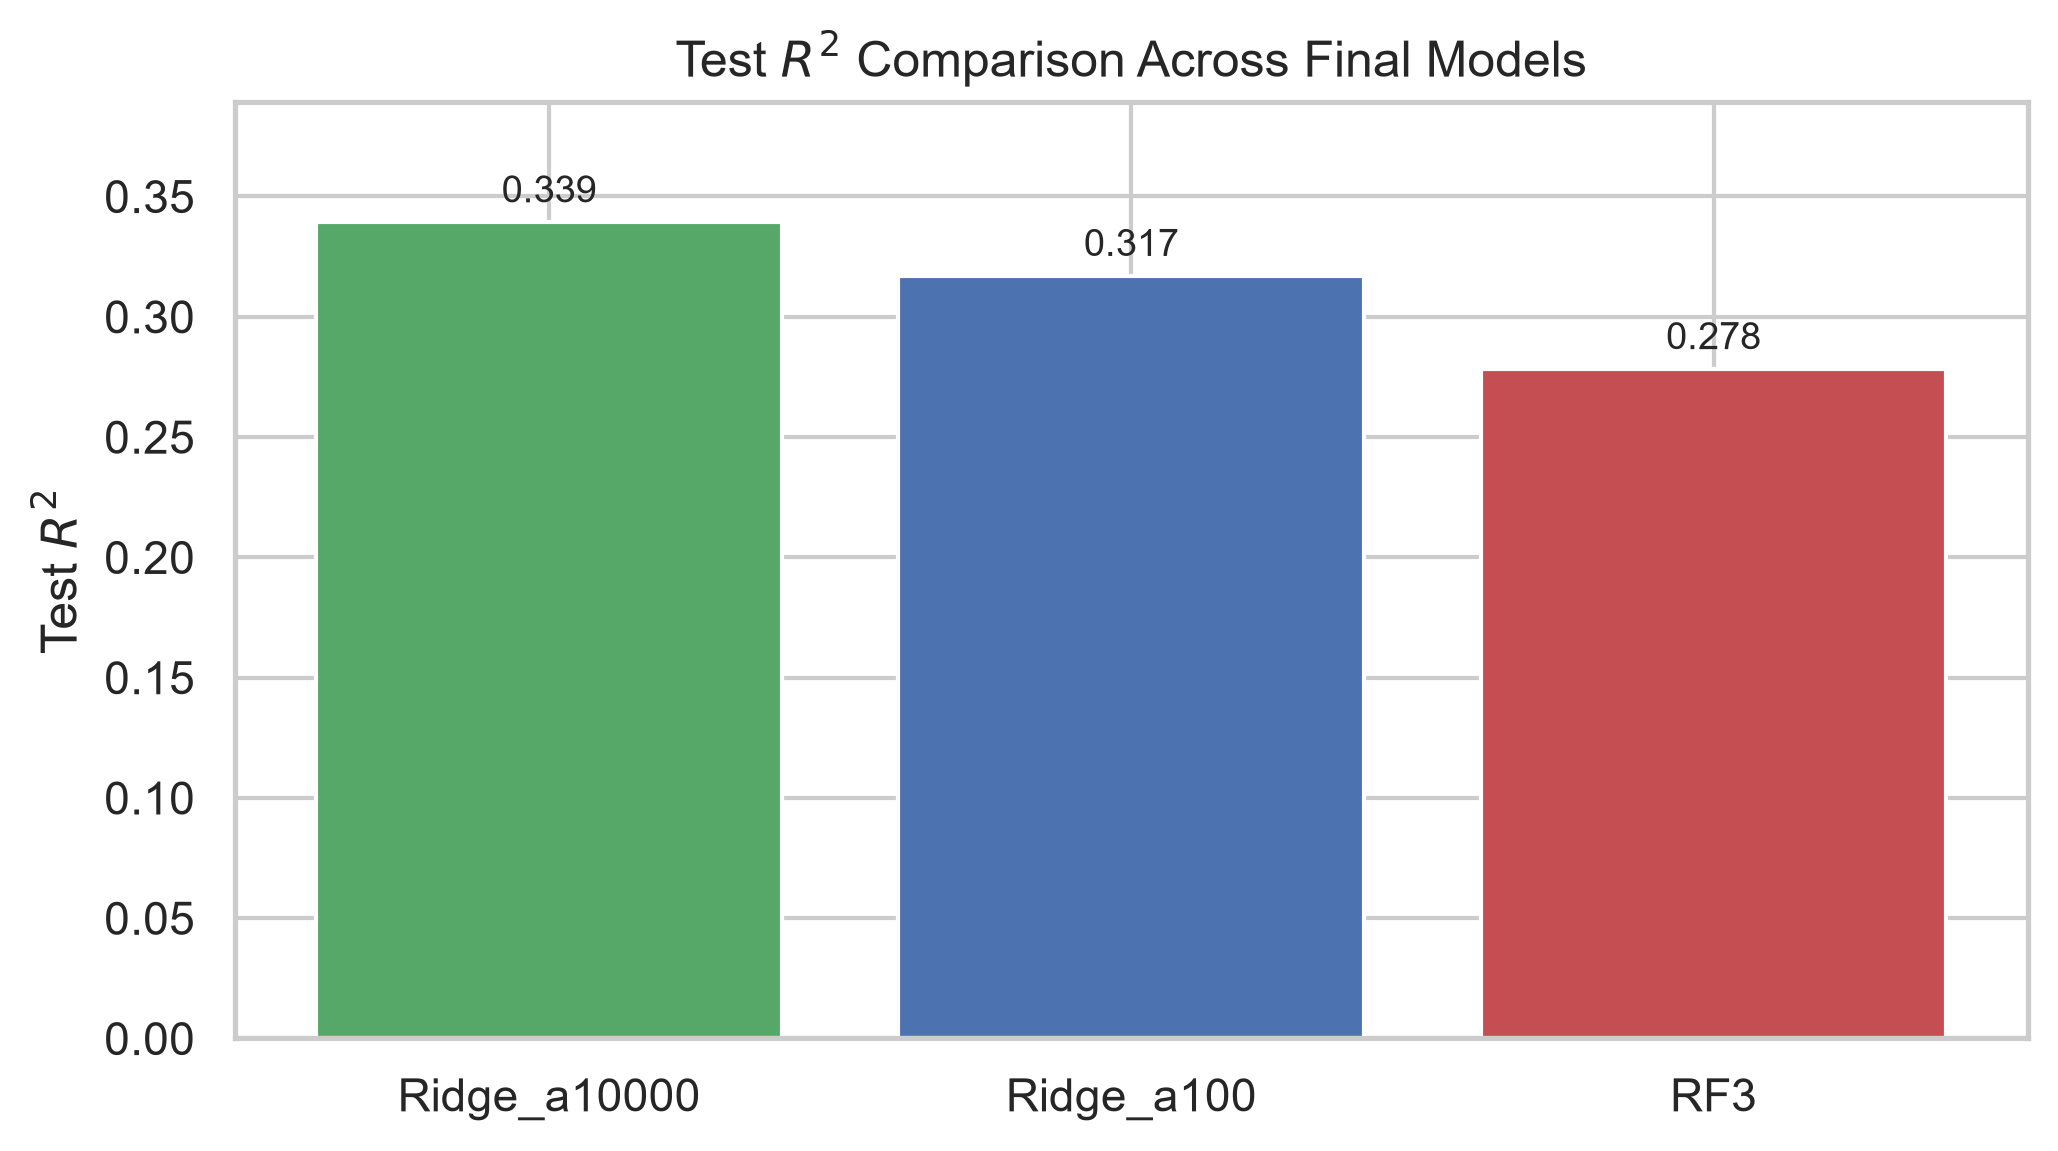

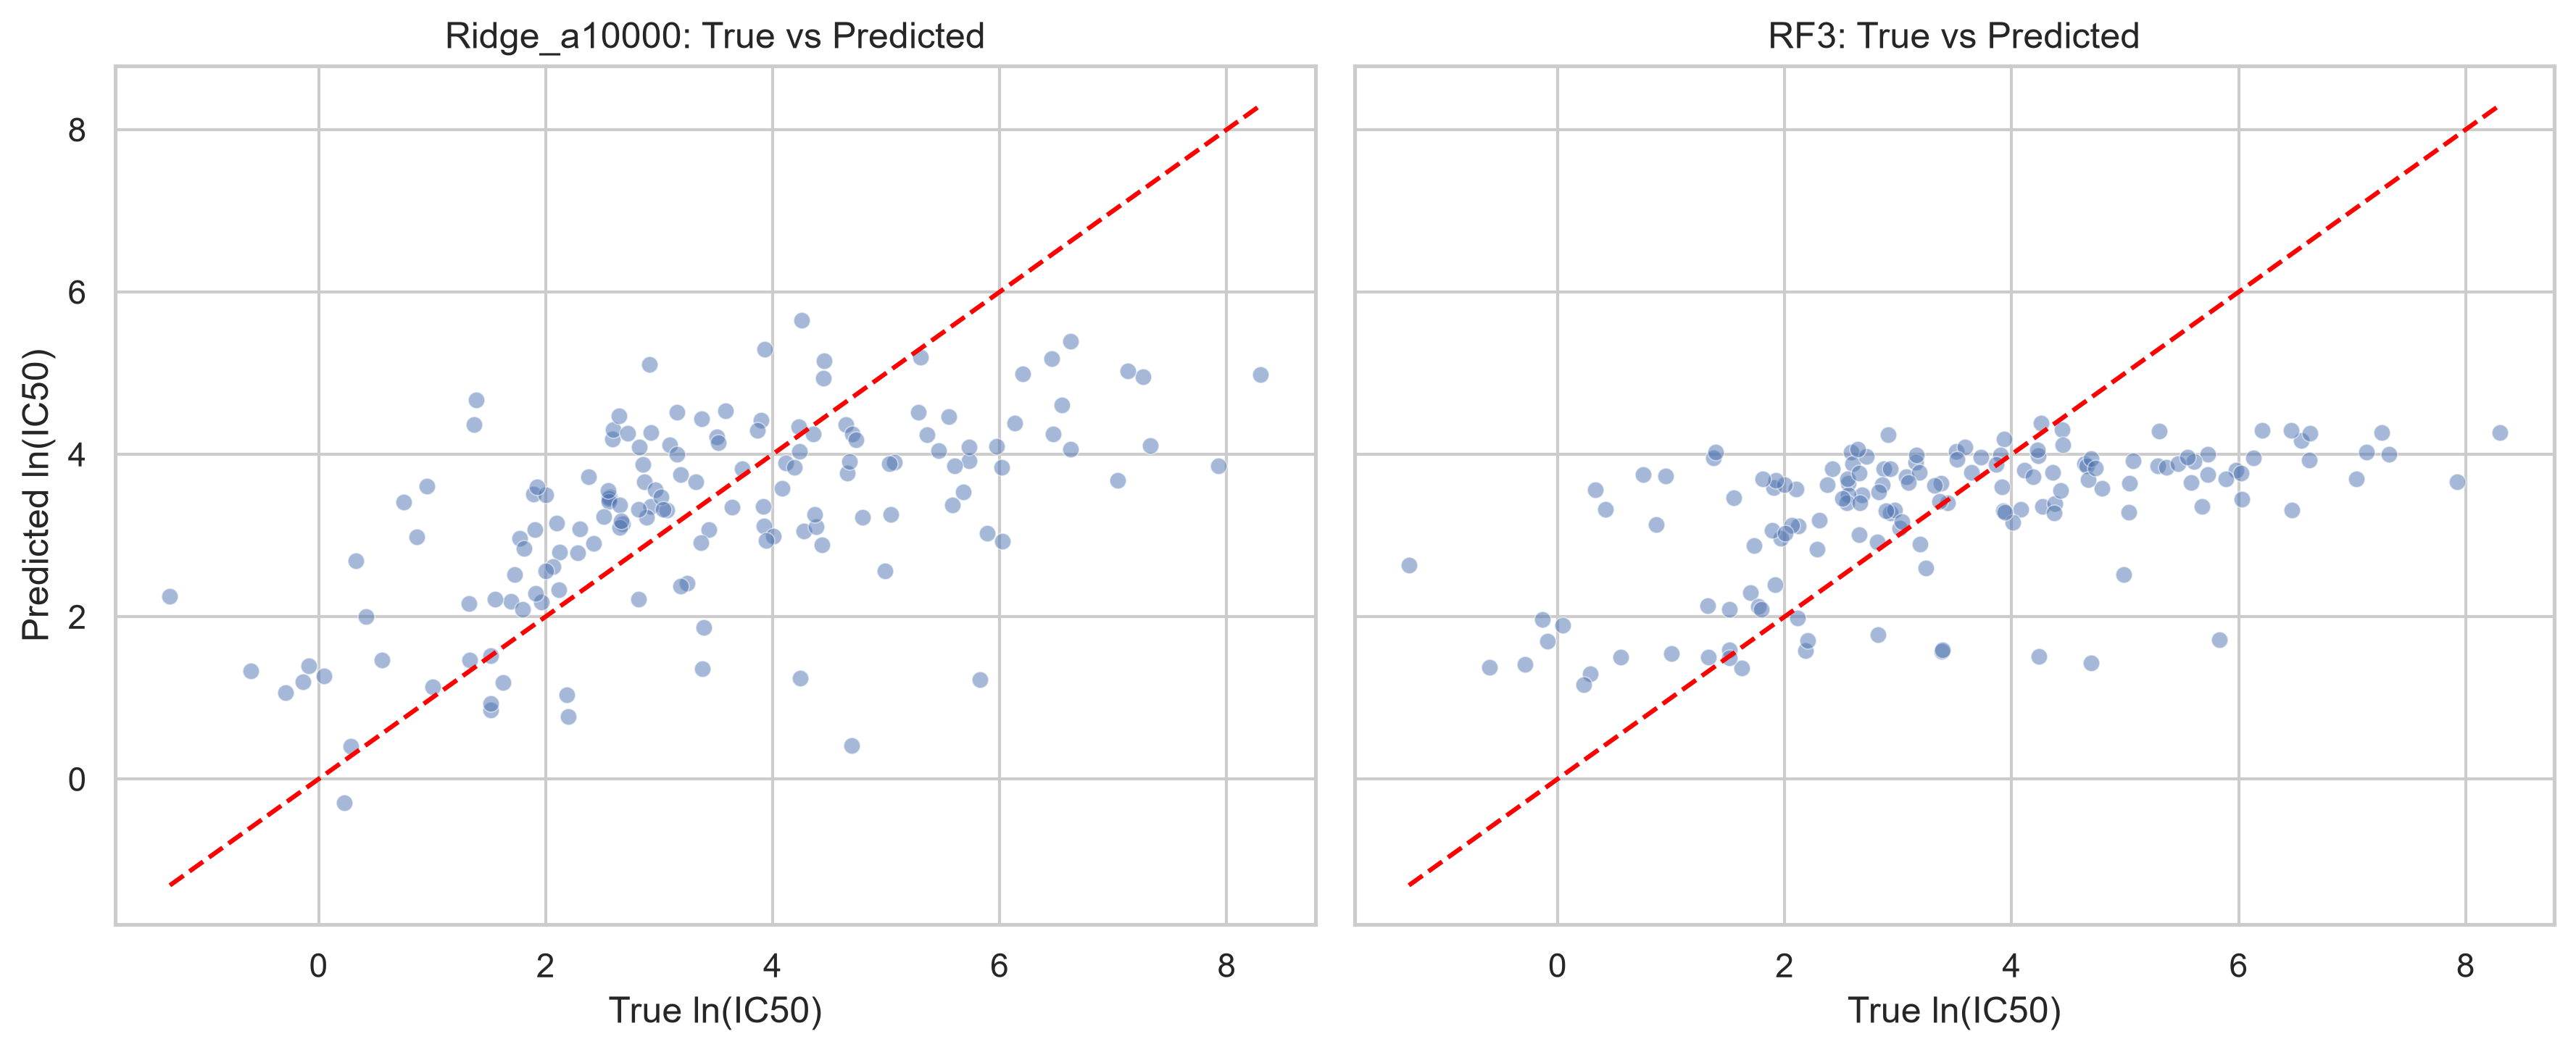

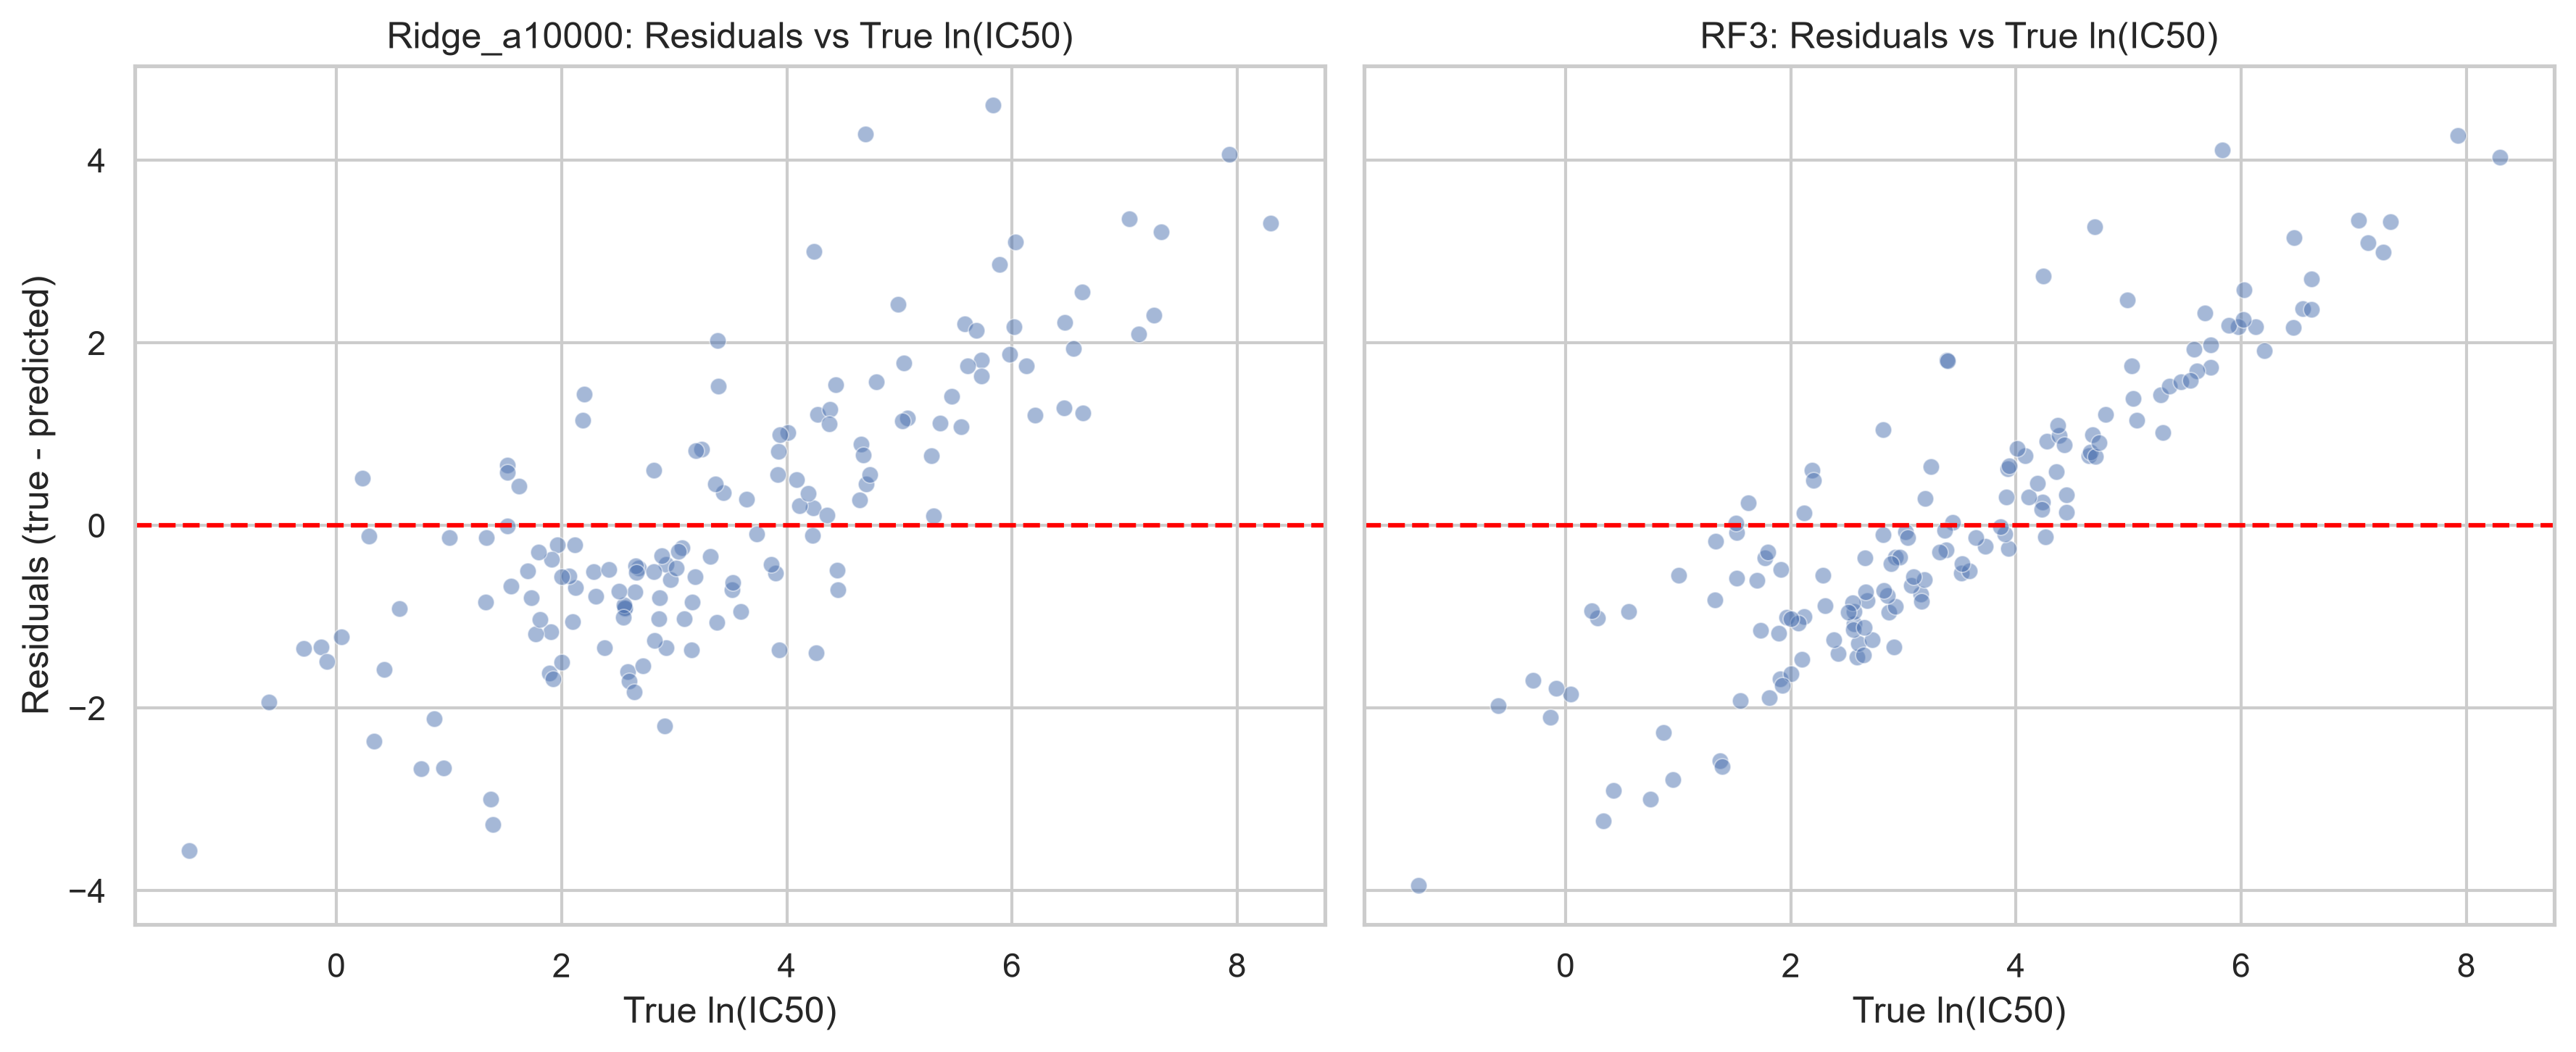

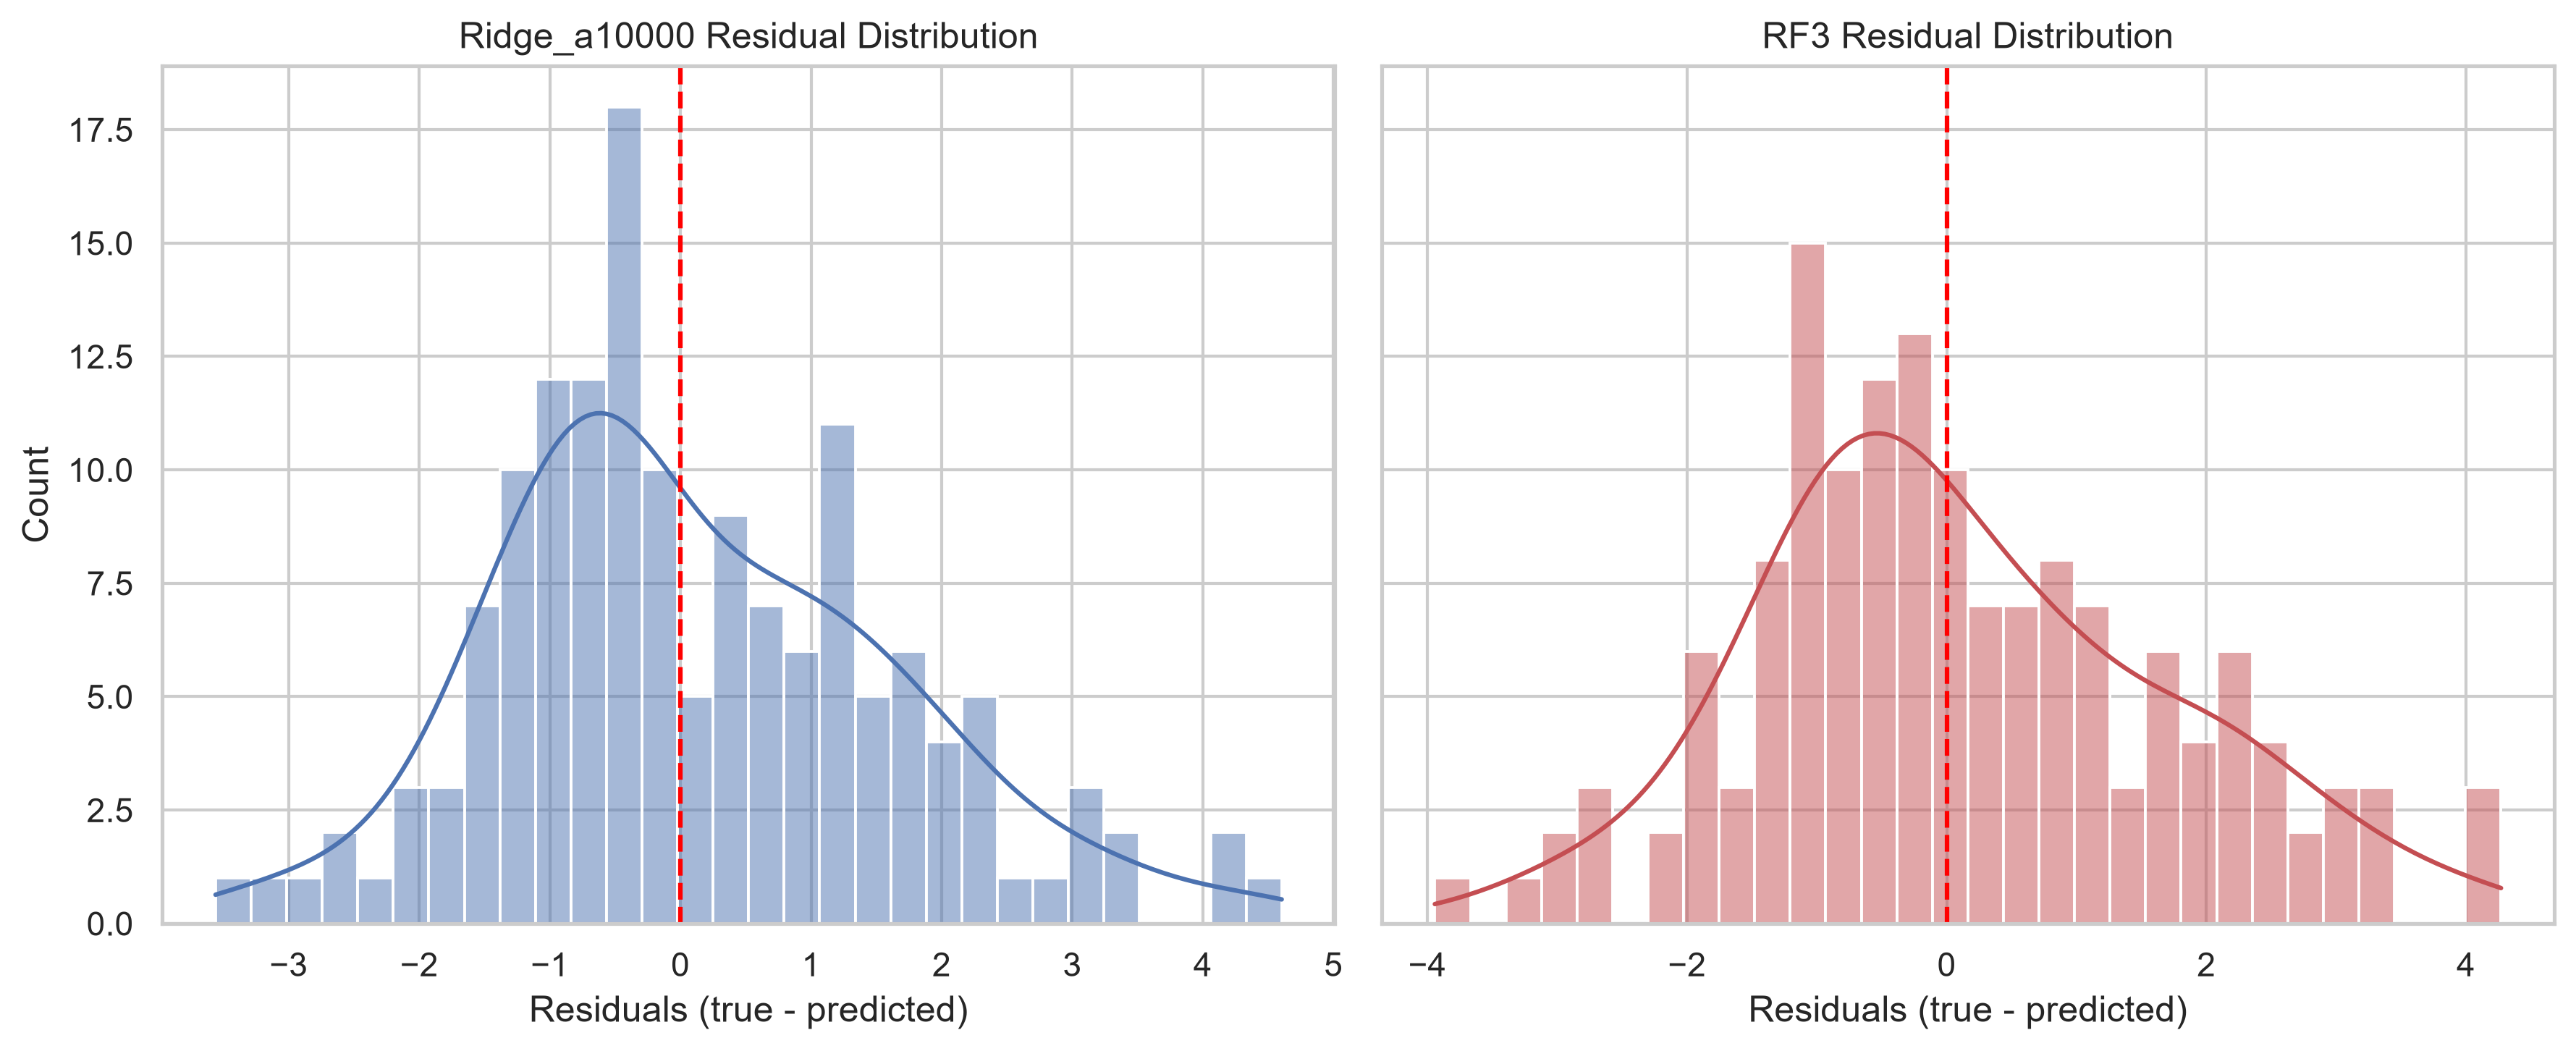

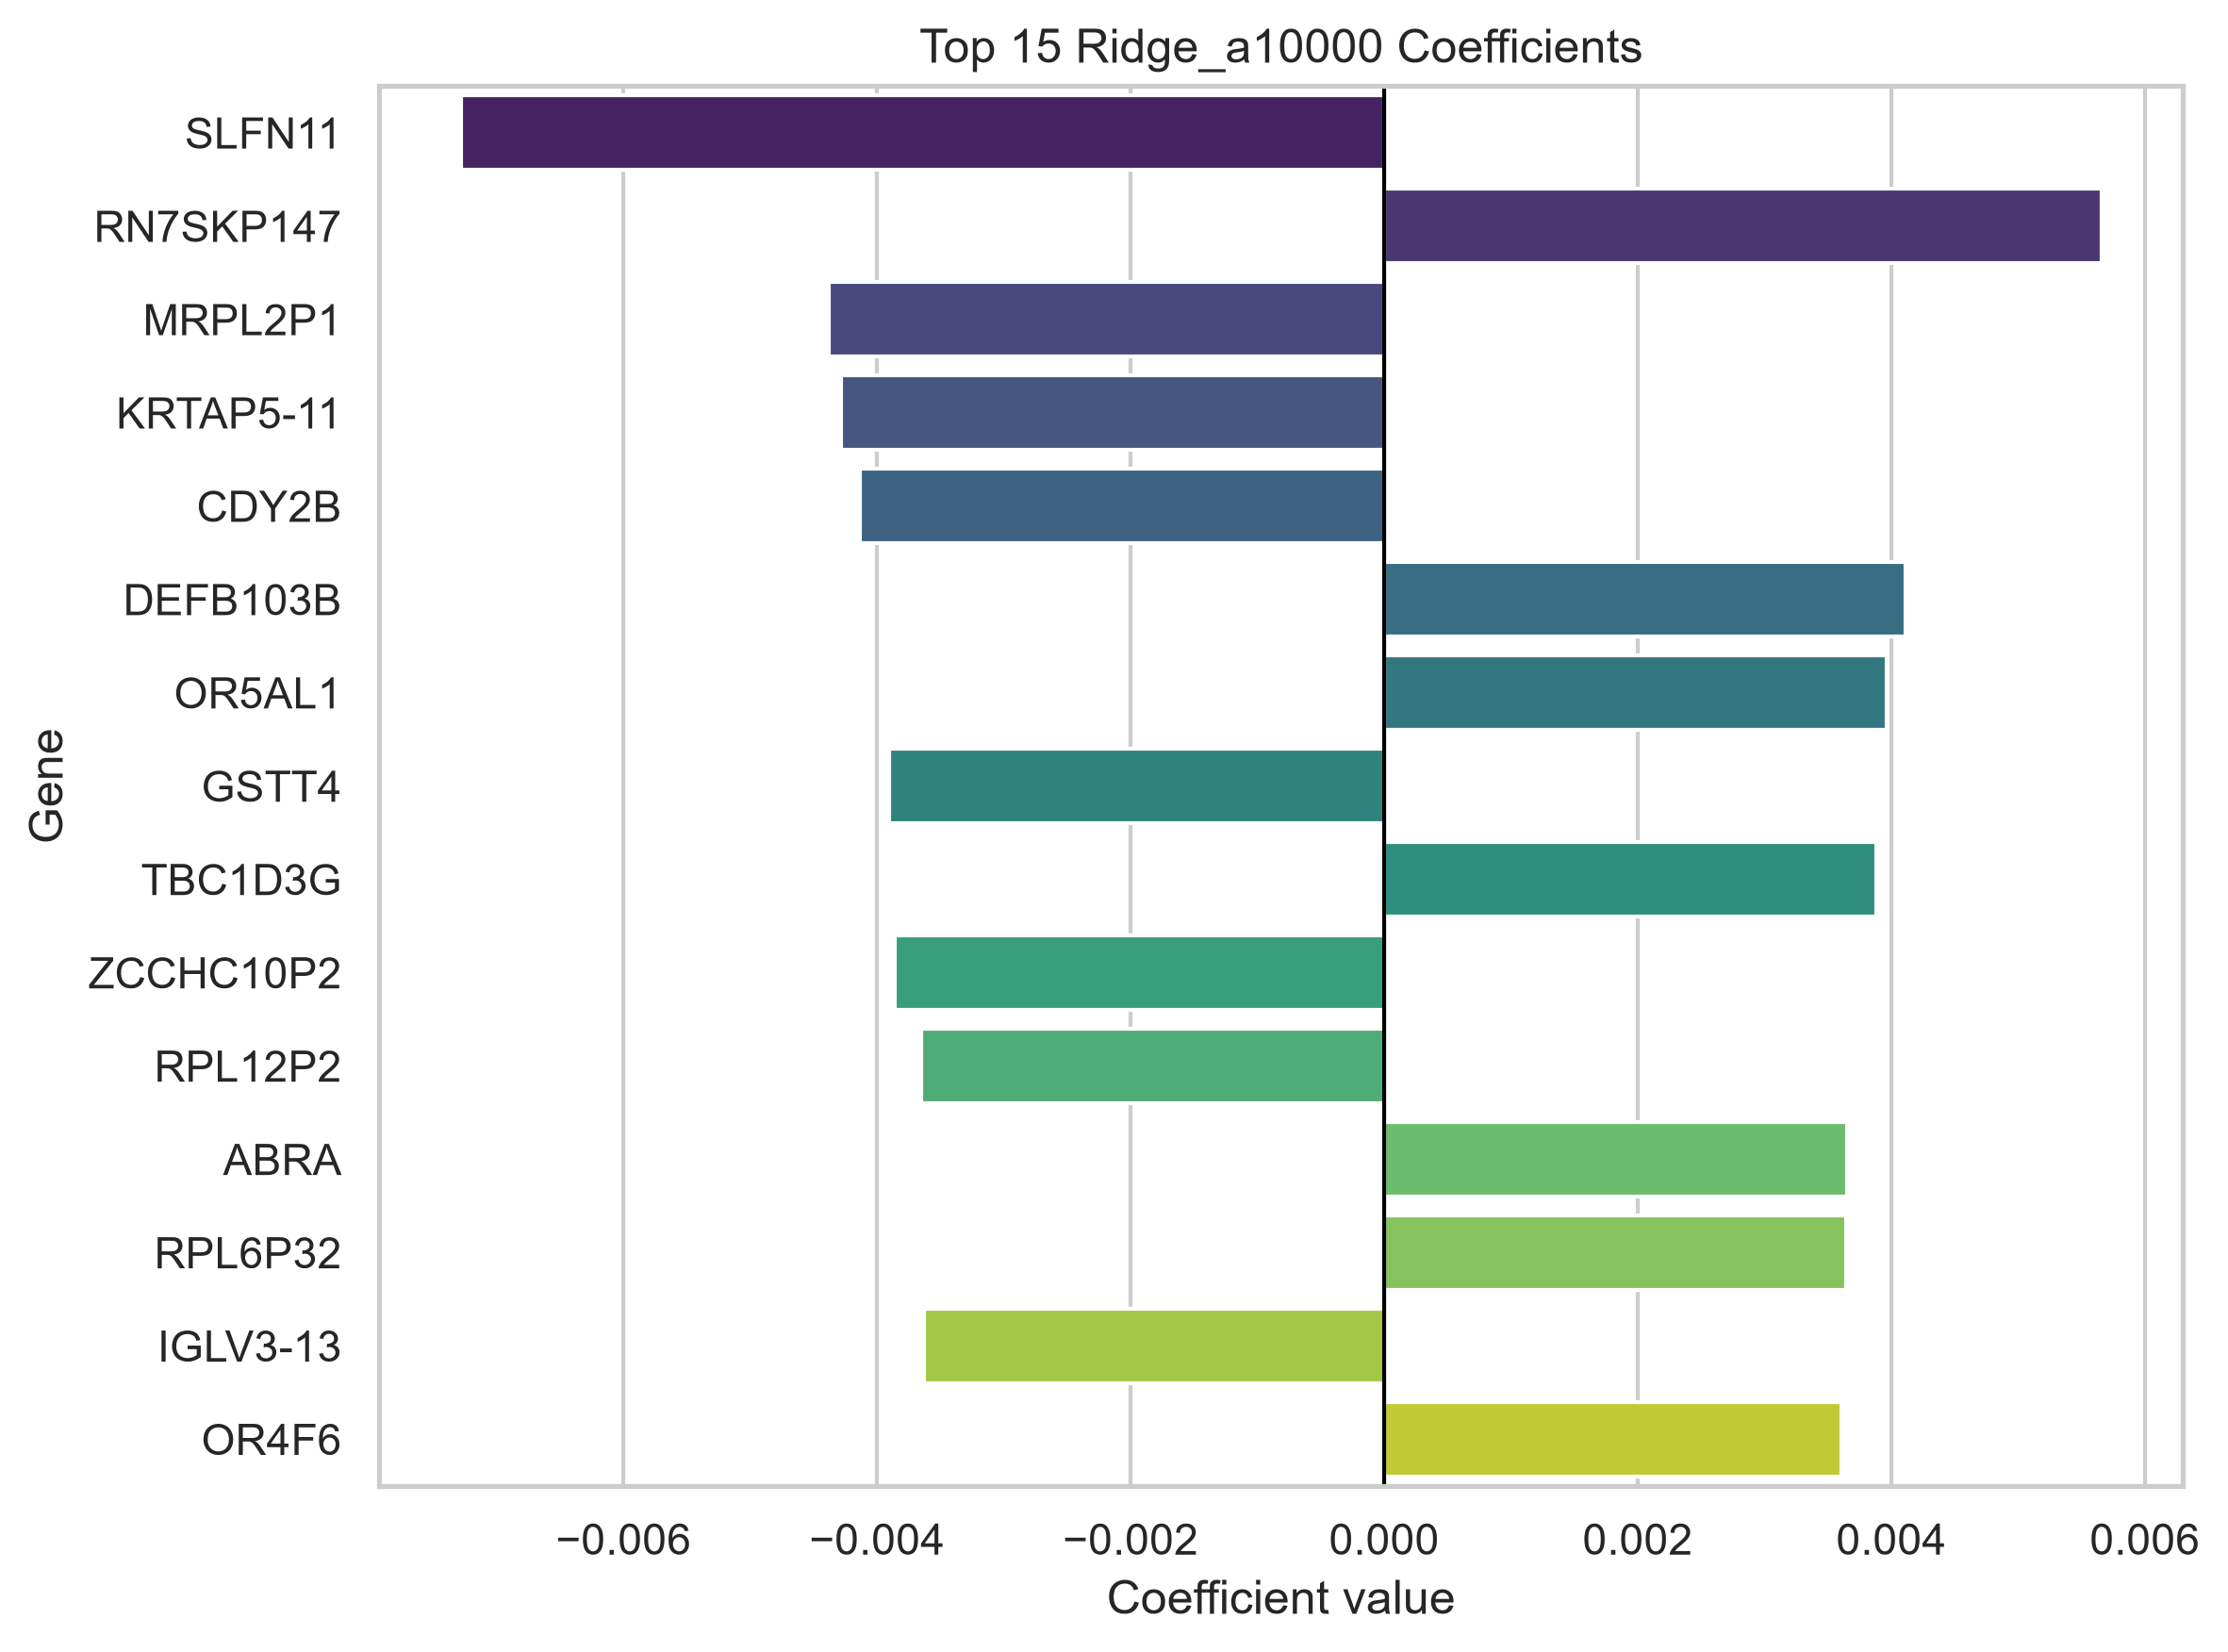

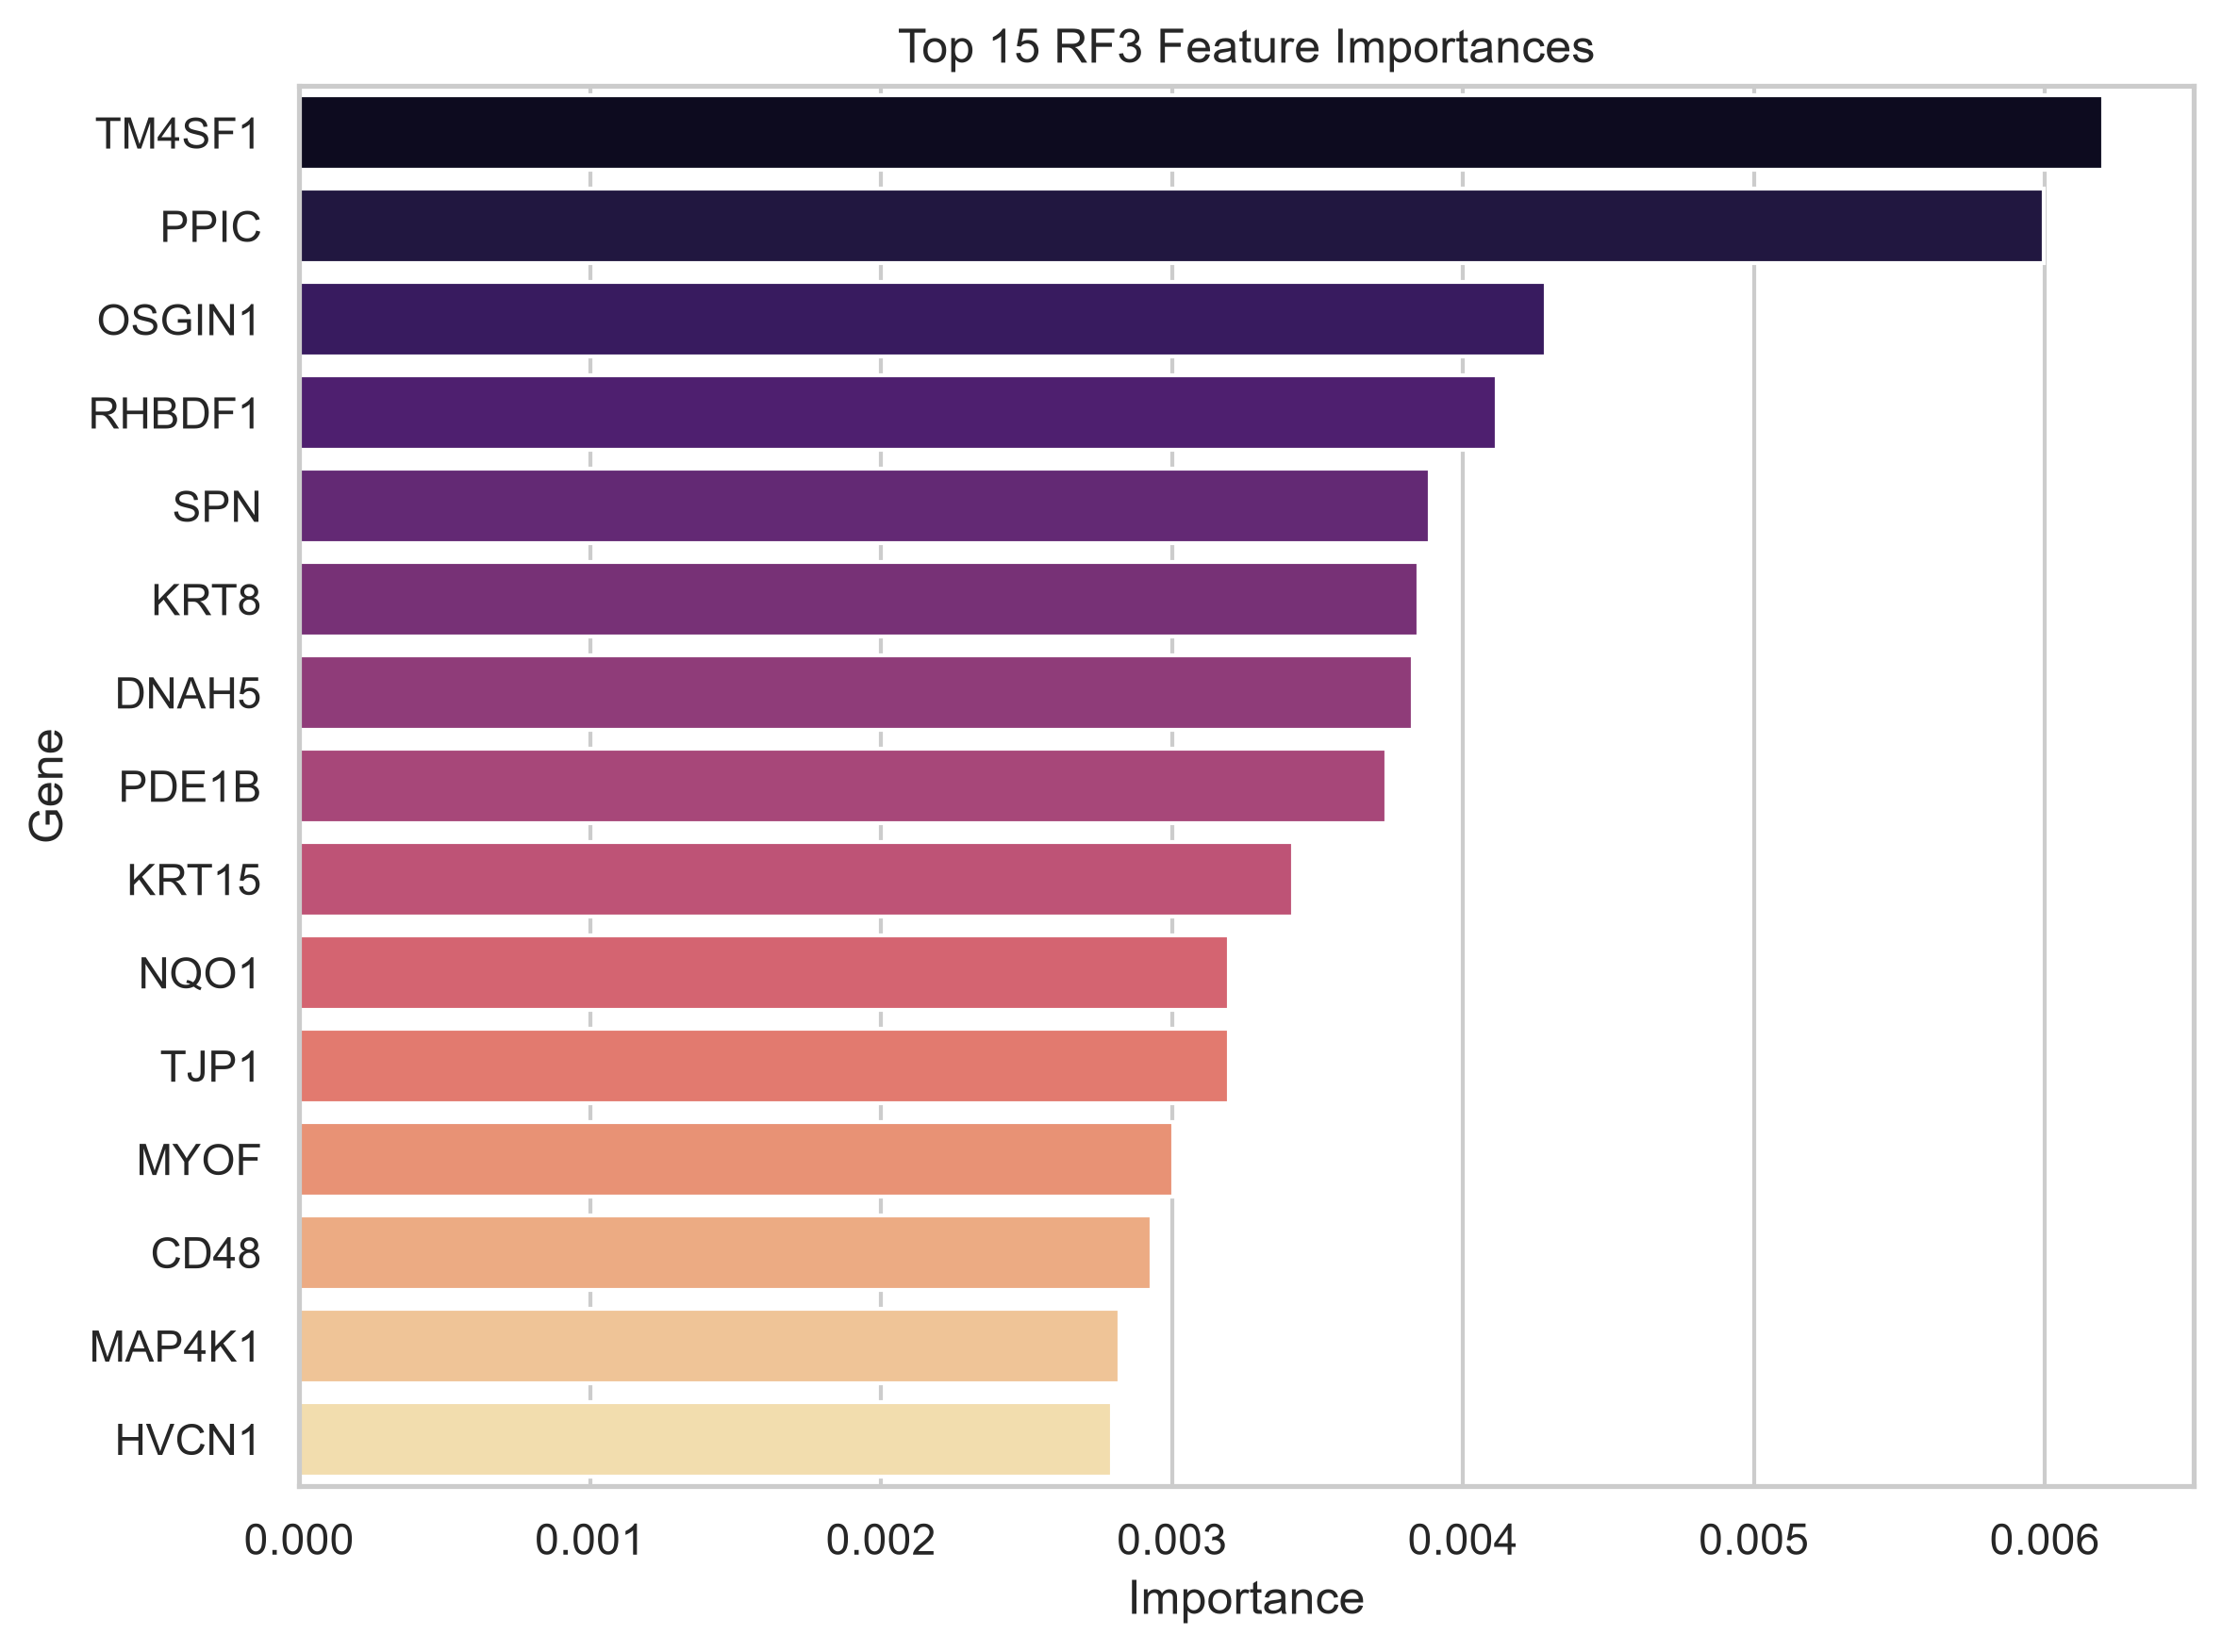

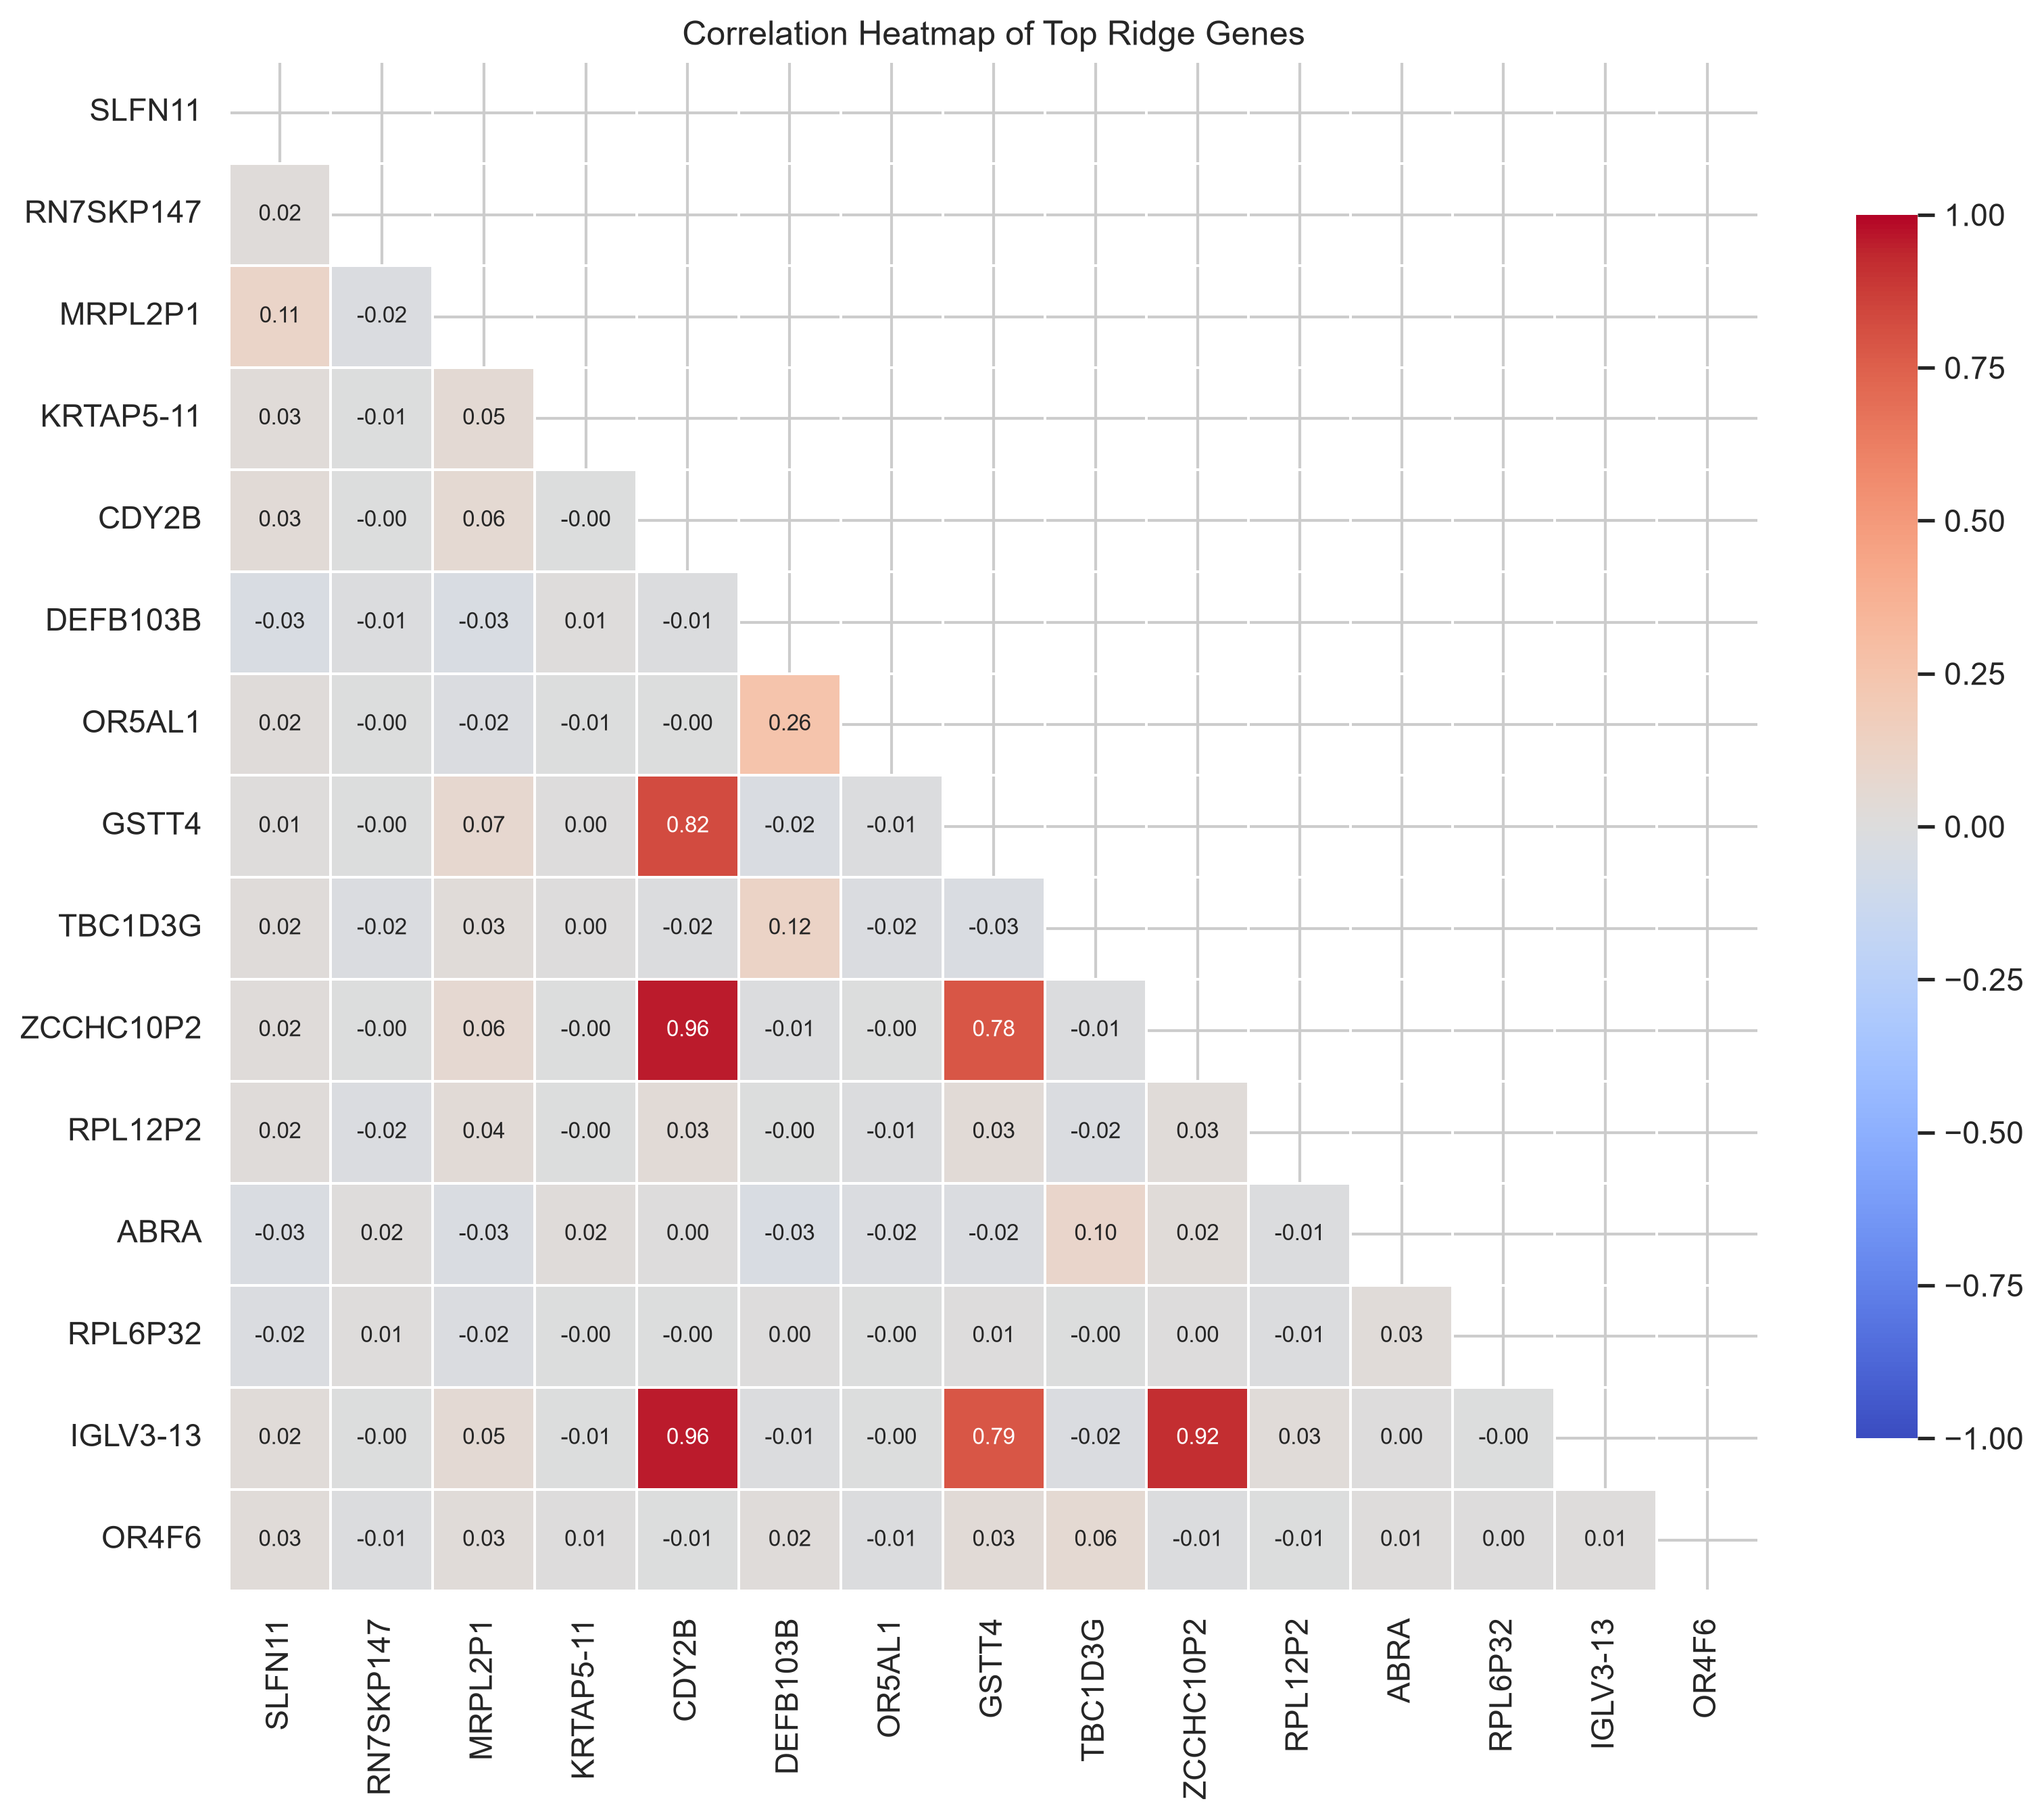

In [3]:
# Show saved figures

figure_files = [
    "model_test_r2_comparison.png",
    "predicted_vs_true_ridge_rf.png",
    "residuals_vs_true_ridge_rf.png",
    "residual_distribution_ridge_rf.png",
    "ridge_a10000_top_coefficients.png",
    "rf3_top_feature_importances.png",
    "top_gene_correlation_heatmap.png",
]

for fname in figure_files:
    display(Image(filename=str(figures_dir / fname)))

In [4]:
# Final metrics table

ridge_test_pred = ridge_a10000.predict(X_test)
rf3_test_pred = rf3.predict(X_test)

results_df = pd.DataFrame({
    "model": ["Ridge_a10000", "RF3"],
    "test_r2": [
        r2_score(y_test, ridge_test_pred),
        r2_score(y_test, rf3_test_pred),
    ],
    "test_mse": [
        mean_squared_error(y_test, ridge_test_pred),
        mean_squared_error(y_test, rf3_test_pred),
    ],
    "test_rmse": [
        np.sqrt(mean_squared_error(y_test, ridge_test_pred)),
        np.sqrt(mean_squared_error(y_test, rf3_test_pred)),
    ],
    "test_mae": [
        mean_absolute_error(y_test, ridge_test_pred),
        mean_absolute_error(y_test, rf3_test_pred),
    ],
})

results_df

,model,test_r2,test_mse,test_rmse,test_mae
0,Ridge_a10000,0.339243,2.340909,1.530003,1.222917
1,RF3,0.278231,2.557061,1.599081,1.267344


In [5]:
# List top Ridge genes in a table

coef_df = pd.DataFrame({
    "gene": feature_names,
    "coef": ridge_a10000[-1].coef_
})

top_coef_df = coef_df.reindex(coef_df["coef"].abs().sort_values(ascending=False).index).head(15)
top_coef_df

,gene,coef
30032,SLFN11,-0.007281
25140,RN7SKP147,0.005655
18109,MRPL2P1,-0.004381
13758,KRTAP5-11,-0.004287
4117,CDY2B,-0.004136
6226,DEFB103B,0.004110
21051,OR5AL1,0.003964
10369,GSTT4,-0.003909
31910,TBC1D3G,0.003882
35476,ZCCHC10P2,-0.003862


In [6]:
# List top Random Forest 3 genes in a table

rf_importance_df = pd.DataFrame({
    "gene": feature_names,
    "importance": rf3[-1].feature_importances_
})

top_rf_df = rf_importance_df.sort_values("importance", ascending=False).head(15)
top_rf_df

,gene,importance
32496,TM4SF1,0.006201
23203,PPIC,0.005995
21429,OSGIN1,0.004284
24955,RHBDF1,0.004116
30942,SPN,0.003887
13614,KRT8,0.003846
6571,DNAH5,0.003827
22002,PDE1B,0.003735
13481,KRT15,0.003416
20059,NQO1,0.003196


In [8]:
# Do the models agree on any genes?

ridge_top_genes = set(top_coef_df["gene"])
rf_top_genes = set(top_rf_df["gene"])

overlap_genes = sorted(ridge_top_genes.intersection(rf_top_genes))

overlap_df = pd.DataFrame({
    "shared_gene": overlap_genes
})

print("Number of overlapping genes:", len(overlap_genes))
overlap_df

Number of overlapping genes: 0


,shared_gene
